# 01 – Veri Temizliği ve Keşifsel Veri Analizi (EDA)
**Hafta:** H3–H4 (02.11 – 15.11) · **Puanlama:** EDA ve ön işleme %20 · **Slaytlar:** 20–30

**Amaç:** Veriyi tanımak; kalite sorunlarını, dengesizliği ve modellemeyi etkileyecek özellikleri bulmak.
Bu notebook'ta **model eğitilmez**. Temizlik kararı en sonda verilir.

Her adım: başlık → sözde kod → küçük kod hücresi → çıktı → 1–2 cümle yorum.

### Adım 0: Kurulum
*Slayt 55*

**Ne yapıyoruz:** Kütüphaneleri ve proje kodunu yüklüyoruz.

In [1]:
# proje kökünü Python yoluna ekle (src/ klasörünü kullanabilmek için)
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

# kütüphaneler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# proje kodu
from src import config
from src.data import load_raw, clean

pd.set_option("display.max_columns", 50)

### Adım 1: Veriyi yükle ve ilk bakış
*Slayt 15–16, 20*

**Ne yapıyoruz:** Veriyi okuyup kaç satır (örnek) ve kaç sütun (değişken) olduğuna bakıyoruz.

**Sözde kod (slayt 57):**
```
veri = dosyayı oku
satır ve sütun sayısını yazdır
ilk 5 satırı göster
```

In [2]:
# veriyi yükle
raw = load_raw()

# boyut: (satır, sütun)
print("Boyut:", raw.shape)

# ilk satırlar
raw.head()

Boyut: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


**Yorum:** (Her satır bir oturum, her sütun bir değişken. Hedef sütun hangisi?)

### Adım 2: Değişken tipleri
*Slayt 21, 24*

**Ne yapıyoruz:** Hangi sütunlar sayısal, hangileri kategorik? Sayıyla kodlanmış ama aslında kategori olanlar var mı?

**Sözde kod (slayt 57):**
```
her sütunun veri tipini yazdır
sayıyla kodlanmış kategorikleri işaretle
```

In [3]:
# sütunların veri tipleri
raw.dtypes

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object

**Yorum:** 

### Adım 3: Veri kalitesi: eksik değer ve tekrar eden satır
*Slayt 22–23*

**Ne yapıyoruz:** Eksik değer, birebir tekrar eden satır ve mantıksız değer (ör. negatif süre) var mı?

**Sözde kod (slayt 57):**
```
her sütundaki eksik değer sayısını say
tekrar eden satır sayısını say
tekrar eden satırlar nasıl satırlar? incele
sayısal sütunlarda negatif / aralık dışı değer var mı?
Month yazımlarını listele
```

**Kontrol soruları:**
- Tekrar eden satırlar bölmeden önce mi silinmeli, sonra mı? Neden? (slayt 35, 37)
- `Month` sütunundaki değerlerin yazımı tutarlı mı?

In [4]:
# eksik değerler: boş hücre varsa modelden önce doldurmak ya da silmek gerekir
missing = raw.isna().sum()
print("Toplam eksik değer:", missing.sum())

# tekrar eden satırlar: birebir aynı satırlar bölmede eğitim ve teste dağılabilir
dup_mask = raw.duplicated()
print("Tekrar eden satır:", dup_mask.sum())

Toplam eksik değer: 0
Tekrar eden satır: 125


In [5]:
# tekrar eden satırlar nasıl satırlar? veri hatası mı, gerçekten aynı görünen oturumlar mı?
dups = raw[dup_mask]
print("Tekrarlarda alışveriş oranı:", round(dups[config.TARGET].mean(), 3))

# birkaç tipik sütunun medyanı: bu oturumlar ne kadar "dolu"?
look_cols = ["ProductRelated", "ProductRelated_Duration", "PageValues", "BounceRates", "ExitRates"]
dups[look_cols].median()

Tekrarlarda alışveriş oranı: 0.0


ProductRelated             1.0
ProductRelated_Duration    0.0
PageValues                 0.0
BounceRates                0.2
ExitRates                  0.2
dtype: float64

In [6]:
# mantıksız değerler: sayfa sayısı ve süre negatif olamaz
negatives = (raw[config.NUM_COLS] < 0).sum()
print("Negatif değer sayısı:", negatives.sum())

# oranlar ve SpecialDay tanım gereği 0 ile 1 arasında olmalı
rate_cols = ["BounceRates", "ExitRates", "SpecialDay"]
raw[rate_cols].agg(["min", "max"])

Negatif değer sayısı: 0


,BounceRates,ExitRates,SpecialDay
min,0.0,0.0,0.0
max,0.2,0.2,1.0


In [7]:
# Month yazımları: zaman bölmesi ay adlarıyla yapılacağı için yazım tutarlı olmalı
raw["Month"].value_counts()

Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64

**Yorum:** Eksik ve mantıksız değer yok. 125 tekrarın hepsi tek ürün sayfasında 0 saniye kalıp çıkan, alışverişsiz oturumlar; bölmeden önce silinecekler (Adım 10), yoksa aynı satır hem eğitimde hem testte olup skoru şişirebilir. `Month`'ta Haziran `June` yazılmış, Ocak ve Nisan hiç yok; zaman bölmesi `config.MONTH_ORDER`'daki bu yazımı kullanıyor.

### Adım 4: Hedef değişken ve dengesizlik
*Slayt 27, 46*

**Ne yapıyoruz:** `Revenue` sınıflarının dağılımına bakıyoruz.

**Sözde kod (slayt 57):**
```
Revenue değerlerini say (adet ve oran)
çubuk grafik çiz
herkese 'almaz' deseydik accuracy kaç olurdu?
```

**Kontrol soruları:**
- Bu dağılım metrik seçimini nasıl etkiliyor?

          adet   oran
Revenue              
False    10422  0.845
True      1908  0.155
Herkese 'almaz' accuracy: 0.845


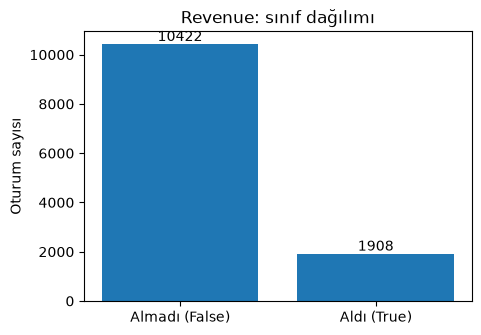

In [8]:
# sınıf sayıları ve oranları
counts = raw[config.TARGET].value_counts()
ratios = raw[config.TARGET].value_counts(normalize=True).round(3)
print(pd.DataFrame({"adet": counts, "oran": ratios}))

# herkese 'almaz' deseydik accuracy = çoğunluk sınıfının oranı olurdu
print("Herkese 'almaz' accuracy:", ratios.max())

# çubuk grafik (sunumda da kullanılacak); reindex: sıra önce False sonra True olsun
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(["Almadı (False)", "Aldı (True)"], counts.reindex([False, True]))
ax.bar_label(bars)
ax.set_ylabel("Oturum sayısı")
ax.set_title("Revenue: sınıf dağılımı")
fig.savefig(config.FIG_DIR / "01_hedef_dagilimi.png", dpi=150, bbox_inches="tight")
plt.show()

**Yorum:** Oturumların %84,5'i alışverişsiz, %15,5'i alışverişli; veri dengesiz. Herkese "almaz" diyen model hiçbir şey öğrenmeden %84,5 accuracy alır ama tek bir alıcıyı yakalayamaz. Bu yüzden ana metrik accuracy değil **PR-AUC** (yanında precision, recall, F1) olacak ve bölmeler bu oranı korumak için tabakalı (stratified) yapılacak.

### Adım 5: Sayısal değişkenler: dağılım, çarpıklık, aykırı değer
*Slayt 25–26*

**Ne yapıyoruz:** Sayısal değişkenlerin özet istatistiklerine ve dağılımlarına bakıyoruz.

**Sözde kod (slayt 57):**
```
describe() ile özet istatistik
süre değişkenlerinin histogramı
aykırı değerler hata mı, gerçek davranış mı? karar ver
```

**Kontrol soruları:**
- Hangi değişkenler çok çarpık? Log dönüşümü gerekir mi?
- Hangi değişkenlerin ölçeği çok farklı? Bu hangi modelleri etkiler? (slayt 25)

In [9]:
# özet istatistikler: ortalama ile medyan (%50) çok farklıysa dağılım çarpıktır
summary = raw[config.NUM_COLS].describe().T

# çarpıklık (skewness): 0'a yakın = simetrik, 1'den büyük = sağa çok çarpık
summary["skew"] = raw[config.NUM_COLS].skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
Administrative,12330.0,2.32,3.32,0.0,0.00,1.00,4.00,27.00,1.96
Administrative_Duration,12330.0,80.82,176.78,0.0,0.00,7.50,93.26,3398.75,5.62
Informational,12330.0,0.50,1.27,0.0,0.00,0.00,0.00,24.00,4.04
Informational_Duration,12330.0,34.47,140.75,0.0,0.00,0.00,0.00,2549.38,7.58
ProductRelated,12330.0,31.73,44.48,0.0,7.00,18.00,38.00,705.00,4.34
ProductRelated_Duration,12330.0,1194.75,1913.67,0.0,184.14,598.94,1464.16,63973.52,7.26
BounceRates,12330.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20,2.95
ExitRates,12330.0,0.04,0.05,0.0,0.01,0.03,0.05,0.20,2.15
PageValues,12330.0,5.89,18.57,0.0,0.00,0.00,0.00,361.76,6.38
SpecialDay,12330.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00,3.30


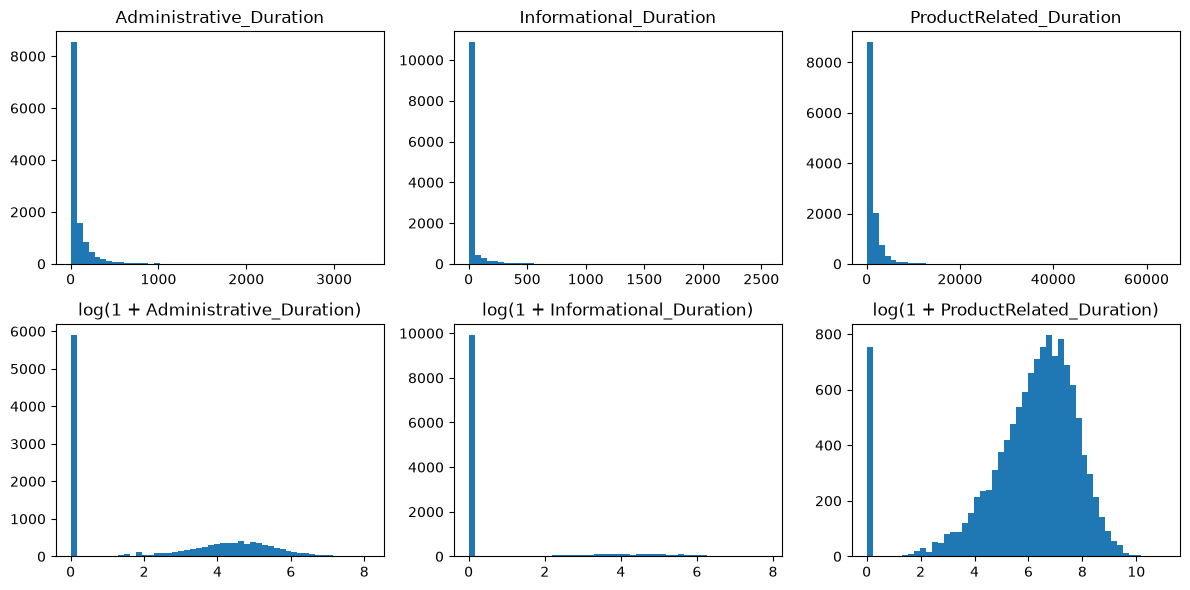

In [10]:
# süre değişkenleri: üst satır ham değer, alt satır log(1 + x)
dur_cols = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for i, col in enumerate(dur_cols):
    axes[0, i].hist(raw[col], bins=50)
    axes[0, i].set_title(col)
    # log1p: 0 saniyeyi bozmadan uzun kuyruğu sıkıştırır
    axes[1, i].hist(np.log1p(raw[col]), bins=50)
    axes[1, i].set_title("log(1 + " + col + ")")
fig.tight_layout()
fig.savefig(config.FIG_DIR / "01_sure_dagilimlari.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# aykırı değer: tipik değer (medyan), en uç %1 sınırı ve maksimum yan yana
tail = raw[config.NUM_COLS].quantile([0.5, 0.99]).T
tail["max"] = raw[config.NUM_COLS].max()
print(tail.round(2))

# en uzun 5 ürün sayfası oturumu: hata mı, gerçek davranış mı?
longest = raw.nlargest(5, "ProductRelated_Duration")
longest_hours = longest["ProductRelated_Duration"] / 3600
print(pd.DataFrame({"saat": longest_hours.round(1), "sayfa": longest["ProductRelated"], "aldı": longest[config.TARGET]}))

                            0.5     0.99       max
Administrative             1.00    14.00     27.00
Administrative_Duration    7.50   830.59   3398.75
Informational              0.00     6.00     24.00
Informational_Duration     0.00   716.39   2549.38
ProductRelated            18.00   221.00    705.00
ProductRelated_Duration  598.94  8701.14  63973.52
BounceRates                0.00     0.20      0.20
ExitRates                  0.03     0.20      0.20
PageValues                 0.00    85.50    361.76
SpecialDay                 0.00     1.00      1.00
      saat  sayfa   aldı
8071  17.8    449  False
5152  12.0    705  False
9238   8.3    343  False
8784   7.5    517   True
8308   6.9    584  False


**Yorum:** Bütün sayısal değişkenler sağa çarpık (skew 2–7,6); süreler ve PageValues'ta ortalama medyanın çok üstünde. Ölçekler çok farklı (süre 64.000 saniyeye kadar, oranlar 0–0,2), bu yüzden lojistik regresyonda ölçekleme şart; ağaç modelleri ölçekten etkilenmez (slayt 25). En uç değerler (ör. 17,8 saatlik oturum) muhtemelen açık bırakılmış sekme ama hata değil, gerçek davranış; silmiyoruz. Log dönüşümü ileride lojistik regresyon için "tek değişiklik" deneyi olarak denenebilir.

### Adım 6: Kategorik değişkenler
*Slayt 24*

**Ne yapıyoruz:** Kategori sayıları ve sıklıkları. Sayıyla kodlanmış kategoriklerde sayıların sırası anlam taşıyor mu?

**Sözde kod (slayt 57):**
```
her kategorik sütun için benzersiz değer sayısı
en sık kategoriler
çok seyrek kategoriler var mı?
```

In [12]:
# her kategorik sütun: kaç farklı değer var, en sık değer ne, çok seyrek kategori var mı?
rows = []
for col in config.CAT_COLS:
    freq = raw[col].value_counts(normalize=True)
    rows.append({
        "sütun": col,
        "benzersiz": raw[col].nunique(),
        "en sık": freq.index[0],
        "en sık pay": round(freq.iloc[0], 3),
        "%1'den seyrek kategori": (freq < 0.01).sum(),
    })
pd.DataFrame(rows).set_index("sütun")

,benzersiz,en sık,en sık pay,%1'den seyrek kategori
sütun,,,,
Month,10,May,0.273,0
OperatingSystems,8,2,0.535,4
Browser,13,2,0.646,6
Region,9,1,0.388,0
TrafficType,20,2,0.317,9
VisitorType,3,Returning_Visitor,0.856,1
Weekend,2,False,0.767,0


In [13]:
# sayıyla kodlanmış bir değişken: kod büyüdükçe alışveriş oranı düzenli değişiyor mu?
# değişmiyorsa sayının sırası anlamsızdır, sayısal değil kategorik (one-hot) kullanılmalı
traffic = raw.groupby("TrafficType")[config.TARGET].agg(["count", "mean"])
print(traffic.round(3).T)

# one-hot sonrası kaç sütun oluşur? (her kategori ayrı bir 0/1 sütunu)
print("One-hot sütun sayısı:", raw[config.CAT_COLS].nunique().sum())

TrafficType        1         2         3         4        5        6     7   \
count        2451.000  3913.000  2052.000  1069.000  260.000  444.000  40.0   
mean            0.107     0.216     0.088     0.154    0.215    0.119   0.3   

TrafficType       8       9      10      11   12       13      14    15  \
count        343.000  42.000  450.0  247.00  1.0  738.000  13.000  38.0   
mean           0.277   0.095    0.2    0.19  0.0    0.058   0.154   0.0   

TrafficType     16   17    18      19       20  
count        3.000  1.0  10.0  17.000  198.000  
mean         0.333  0.0   0.0   0.059    0.253  
One-hot sütun sayısı: 65


**Yorum:** `TrafficType`'ta kod büyüdükçe alışveriş oranı düzenli değişmiyor (1: %10,7, 2: %21,6, 3: %8,8, ...); yani sayıların sırası anlamsız, bu sütunlar sayısal değil **one-hot** ile kodlanmalı. One-hot sonrası 65 sütun oluşuyor. `TrafficType`, `Browser` ve `OperatingSystems`'te %1'den seyrek kategoriler var (ör. TrafficType 12 ve 17'de sadece 1'er oturum); bunlar eğitim setine hiç düşmeyebilir, bu yüzden Pipeline'daki `OneHotEncoder(handle_unknown="ignore")` önemli. Seyrek kategorileri "diğer" altında toplamak ileride tek değişiklik deneyi olabilir.

### Adım 7: Zaman boyutu: aylar
*Slayt 35*

**Ne yapıyoruz:** Zamana göre bölme deneyi için ayların dağılımına bakıyoruz.

**Sözde kod (slayt 57):**
```
aylara göre oturum sayısı ve alışveriş oranı (config.MONTH_ORDER sırasıyla)
hangi aylar eksik?
SpecialDay hangi aylarda sıfırdan farklı?
```

**Kontrol soruları:**
- Alışveriş oranı aylara göre değişiyorsa zamana göre bölmede ne olur?

In [14]:
# aylara göre oturum sayısı ve alışveriş oranı (takvim sırasıyla)
monthly = raw.groupby("Month")[config.TARGET].agg(["count", "mean"])
monthly = monthly.reindex(config.MONTH_ORDER)
monthly.columns = ["oturum", "alışveriş oranı"]

# her ay zaman bölmesinde hangi sete düşüyor? (config.TIME_SPLIT)
for part, months in config.TIME_SPLIT.items():
    monthly.loc[months, "set"] = part
monthly.round(3)

,oturum,alışveriş oranı,set
Month,,,
Feb,184,0.016,train
Mar,1907,0.101,train
May,3364,0.109,train
June,288,0.101,train
Jul,432,0.153,train
Aug,433,0.176,train
Sep,448,0.192,val
Oct,549,0.209,val
Nov,2998,0.254,test


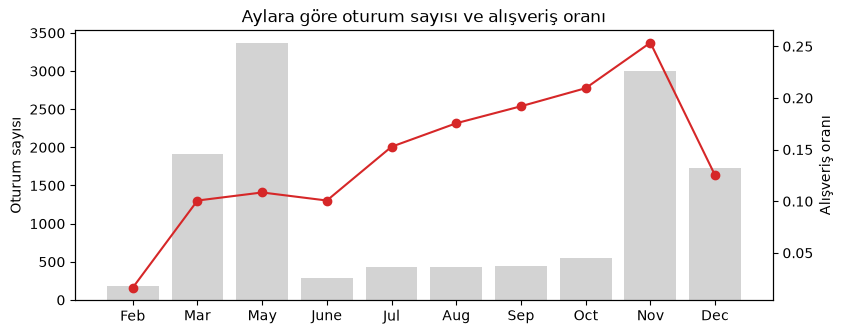

In [15]:
# grafik: çubuk = oturum sayısı (sol eksen), çizgi = alışveriş oranı (sağ eksen)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(monthly.index, monthly["oturum"], color="lightgray")
ax.set_ylabel("Oturum sayısı")
ax2 = ax.twinx()
ax2.plot(monthly.index, monthly["alışveriş oranı"], marker="o", color="tab:red")
ax2.set_ylabel("Alışveriş oranı")
ax.set_title("Aylara göre oturum sayısı ve alışveriş oranı")
fig.savefig(config.FIG_DIR / "01_aylar.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# SpecialDay (özel güne yakınlık) hangi aylarda sıfırdan farklı?
special = raw[raw["SpecialDay"] > 0]
print(special["Month"].value_counts())

# zaman bölmesinin setleri: boyut ve alışveriş oranı (model yok, sadece sayım)
for part, months in config.TIME_SPLIT.items():
    rows = raw[raw["Month"].isin(months)]
    print(part, months, "oturum:", len(rows), "oran:", round(rows[config.TARGET].mean(), 3))

Month
May    1172
Feb      79
Name: count, dtype: int64
train ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug'] oturum: 6608 oran: 0.111
val ['Sep', 'Oct'] oturum: 997 oran: 0.202
test ['Nov', 'Dec'] oturum: 4725 oran: 0.207


**Yorum:** Alışveriş oranı aylara göre çok değişiyor: Şubat'ta %1,6, Kasım'da %25,4. Oturumların yarıdan fazlası Mayıs ve Kasım'da. Zaman bölmesinde eğitim setinin (Şub–Ağu) alışveriş oranı %11,1, doğrulama (Eyl–Eki) %20,2, test (Kas–Ara) %20,7; yani model, alıcıların daha seyrek olduğu bir dönemden öğrenip daha sık olduğu bir dönemde sınanacak (dağılım kayması). Rastgele PR-AUC'un taban değeri pozitif oranına eşit olduğu için iki bölmenin PR-AUC'larını yan yana koyarken bu farkı da yazmalıyız. Doğrulama seti küçük (997 oturum), eşik seçimi gürültülü olabilir. `SpecialDay` sadece Şubat ve Mayıs'ta sıfırdan farklı (Sevgililer Günü, Anneler Günü).

### Adım 8: PageValues ve alışveriş ilişkisi
*Slayt 37–38*

**Ne yapıyoruz:** Sızıntı deneyinin gerekçesi: PageValues alışverişle ne kadar ilişkili?

**Sözde kod (slayt 57):**
```
PageValues = 0 olan oturumların oranı
PageValues > 0 ve = 0 gruplarında alışveriş oranı
alıcıların kaçında PageValues = 0?
```

**Kontrol soruları:**
- Google Analytics'in Page Value tanımına göre bu değer tahmin anında biliniyor mu?

In [17]:
# PageValues sıfır mı, sıfırdan büyük mü?
has_value = raw["PageValues"] > 0
print("PageValues = 0 olan oturum oranı:", round(1 - has_value.mean(), 3))

# iki grupta oturum sayısı ve alışveriş oranı
groups = raw.groupby(has_value)[config.TARGET].agg(["count", "mean"])
groups.index = ["PageValues = 0", "PageValues > 0"]
print(groups.round(3))

# alıcıların kaçında PageValues = 0? (az ise PageValues alıcıları neredeyse tek başına ayırıyor)
buyers = raw[raw[config.TARGET]]
print("Alıcılarda PageValues = 0 oranı:", round((buyers["PageValues"] == 0).mean(), 3))

PageValues = 0 olan oturum oranı: 0.779
                count   mean
PageValues = 0   9600  0.039
PageValues > 0   2730  0.563
Alıcılarda PageValues = 0 oranı: 0.194


In [18]:
# her sayısal değişkenin Revenue ile korelasyonu: PageValues diğerlerinden ne kadar güçlü?
y_int = raw[config.TARGET].astype(int)
corr = raw[config.NUM_COLS].corrwith(y_int)
corr.sort_values(ascending=False).round(3)

PageValues                 0.493
ProductRelated             0.159
ProductRelated_Duration    0.152
Administrative             0.139
Informational              0.095
Administrative_Duration    0.094
Informational_Duration     0.070
SpecialDay                -0.082
BounceRates               -0.151
ExitRates                 -0.207
dtype: float64

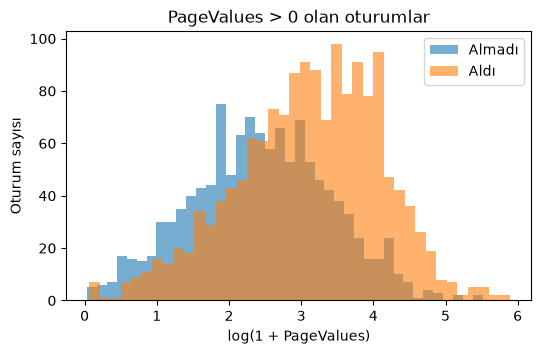

In [19]:
# PageValues > 0 olan oturumlarda: alanlar ve almayanlar (log ölçek)
positive = raw[has_value]
bought = positive[config.TARGET]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(np.log1p(positive.loc[~bought, "PageValues"]), bins=40, alpha=0.6, label="Almadı")
ax.hist(np.log1p(positive.loc[bought, "PageValues"]), bins=40, alpha=0.6, label="Aldı")
ax.set_xlabel("log(1 + PageValues)")
ax.set_ylabel("Oturum sayısı")
ax.set_title("PageValues > 0 olan oturumlar")
ax.legend()
fig.savefig(config.FIG_DIR / "01_pagevalues.png", dpi=150, bbox_inches="tight")
plt.show()

**Yorum:** Oturumların %77,9'unda PageValues = 0 ve bu grupta alışveriş oranı sadece %3,9; PageValues > 0 olanlarda ise %56,3. Revenue ile korelasyonu 0,49; mutlak değerce ikinci sıradaki ExitRates'in (−0,21) iki katından fazla; tek başına alıcıları büyük ölçüde ayırıyor. Google Analytics'te Page Value alışveriş yapılan oturumlardan hesaplandığı için oturumun kendi alışverişi bu değere katkı vermiş olabilir: bu "fazla iyi" ilişki sızıntı şüphesini güçlendiriyor (slayt 37–38). Öte yandan alıcıların %19,4'ünde PageValues = 0, yani değişken hedefin birebir kopyası değil. Sızıntının ne kadar etkili olduğunu bu yüzden 04_deneyler'de modelleri PageValues'lu ve PageValues'suz eğitip ölçeceğiz; "PageValues > 0 ise alır" kuralı da (Baseline 2) güçlü bir rakip olacak.

### Adım 9: Diğer ilişkiler
*Slayt 28*

**Ne yapıyoruz:** `VisitorType`, `Weekend`, `BounceRates`/`ExitRates` ile alışveriş ilişkisi; sayısal değişkenler arası korelasyon.

**Sözde kod (slayt 57):**
```
ziyaretçi tipine göre alışveriş oranı
korelasyon ısı haritası
```

In [20]:
# ziyaretçi tipine göre oturum sayısı ve alışveriş oranı
by_visitor = raw.groupby("VisitorType")[config.TARGET].agg(["count", "mean"])
print(by_visitor.round(3))
print()

# hafta sonu mu, hafta içi mi?
by_weekend = raw.groupby("Weekend")[config.TARGET].agg(["count", "mean"])
print(by_weekend.round(3))
print()

# hemen çıkma ve çıkış oranları: alanlarla almayanlarda ortalama ve medyan
rates = raw.groupby(config.TARGET)[["BounceRates", "ExitRates"]].agg(["mean", "median"])
print(rates.round(3))

                   count   mean
VisitorType                    
New_Visitor         1694  0.249
Other                 85  0.188
Returning_Visitor  10551  0.139

         count   mean
Weekend              
False     9462  0.149
True      2868  0.174

        BounceRates        ExitRates       
               mean median      mean median
Revenue                                    
False         0.025  0.004     0.047  0.029
True          0.005  0.000     0.020  0.016


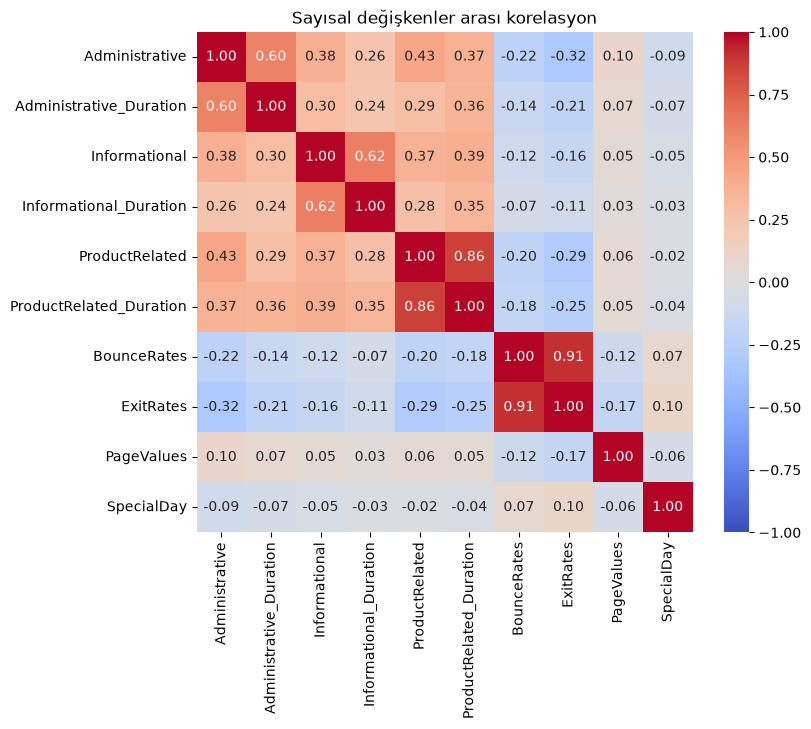

In [21]:
# sayısal değişkenler arası korelasyon: aynı bilgiyi taşıyan değişken çiftleri var mı?
corr_matrix = raw[config.NUM_COLS].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Sayısal değişkenler arası korelasyon")
fig.savefig(config.FIG_DIR / "01_korelasyon.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
# 0,7'den güçlü korelasyonlu çiftleri listele (her çifti bir kez yaz)
for i, col_a in enumerate(config.NUM_COLS):
    for col_b in config.NUM_COLS[i + 1:]:
        r = corr_matrix.loc[col_a, col_b]
        if abs(r) > 0.7:
            print(col_a, "-", col_b, ":", round(r, 2))

ProductRelated - ProductRelated_Duration : 0.86
BounceRates - ExitRates : 0.91


**Yorum:** Beklenenin tersine yeni ziyaretçiler daha çok alışveriş yapıyor (%24,9), geri dönenler daha az (%13,9); geri dönen ziyaretçilerin çoğu sadece göz atıyor olabilir, hata analizinde bu gruba bakmaya değer. Hafta sonu etkisi küçük (%17,4'e karşı %14,9). Alıcıların hemen çıkma ve çıkış oranları belirgin şekilde düşük. İki güçlü çift var: BounceRates–ExitRates (0,91) ve ProductRelated–ProductRelated_Duration (0,86); bu çiftler büyük ölçüde aynı bilgiyi taşıyor, lojistik regresyonun katsayılarını yorumlarken dikkat etmeliyiz ama tahmin için ikisini de tutuyoruz. PageValues diğer değişkenlerle zayıf ilişkili (en fazla 0,17): çıkarıldığında yerini başka bir değişken kolayca dolduramayabilir, sızıntı deneyinde skorun düşmesini bekleyebiliriz.

### Adım 10: Temizlik kararı
*Slayt 22, 35*

**Ne yapıyoruz:** EDA bulgularına göre temizliği uyguluyoruz: `clean()` tekrar eden satırları siler ve True/False'u 0/1 yapar.

**Sözde kod (slayt 57):**
```
df = clean(raw)
satır sayısı ve alışveriş oranı tekrar kontrol
```

In [23]:
# temizliği uygula (bölmeden ÖNCE: tekrarlar bölmeler arasına dağılmasın)
df = clean(raw)

# kontrol
print("Satır:", len(df))
print("Kalan tekrar eden satır:", df.duplicated().sum())
print("Alışveriş oranı:", round(df[config.TARGET].mean(), 3))

Tekrar eden satır silindi: 125  (kalan: 12205)
Satır: 12205
Kalan tekrar eden satır: 0
Alışveriş oranı: 0.156


**Yorum:** 125 tekrar eden satır silindi, 12.205 oturum kaldı ve artık hiç tekrar yok. Silinenlerin hepsi alışverişsiz olduğu için alışveriş oranı %15,5'ten %15,6'ya çıktı; dengesizlik değişmedi. Eksik değer olmadığı için doldurma yapılmadı, aykırı değerler gerçek davranış sayılıp tutuldu (Adım 5). Ölçekleme ve one-hot burada yapılmıyor: bunlar 02_baseline'da bölmeden SONRA, `Pipeline` içinde ve sadece eğitim verisine fit edilecek.

## Bulgular ve kararlar
> Bu hücreyi **kendi cümlelerinizle** yazın. Sunumda ve hocanın kontrolünde bunu savunacaksınız.

- Bulgu 1:
- Bulgu 2:
- Bu bulgulara göre aldığımız karar(lar):
- Deney günlüğüne yazıldı mı? (`reports/deney_gunlugu.md`)
- Git commit atıldı mı?
- `data/README.md` → "Bilinen sınırlamalar" bölümü güncellendi mi?